In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pyproj import Transformer

In [12]:
pwd

'/Users/franciscagomes/ObjectiveWMClass'

In [14]:
# Get data into dataframe
df = pd.read_csv('../PhD/WM_class/WaterMassClassification/Paper1/Cluster_n_sensitivity/WMA_fractions_v2_with_PV_GMM_ensemble.csv')

FileNotFoundError: [Errno 2] No such file or directory: '../PhD/WaterMassClassification/WM_class/Paper1/Cluster_n_sensitivity/WMA_fractions_v2_with_PV_GMM_ensemble.csv'

In [ ]:
n_clusters = 6

In [ ]:
BATHY_PATH = '../../../bathymetry.dat'            # path to 
BATHY_COLS = ['lon', 'lat', 'z']              # <- column order in your file
STRIDE     = 1                                # raise (e.g. 5-20) if the file is huge
RES_M      = 150_000                          # 150 km bins, same as the profiles

bathy_flat = pd.read_csv(
    BATHY_PATH, sep=r'\s+', header=None, names=BATHY_COLS,
    usecols=range(len(BATHY_COLS)), comment='#', skiprows=0,
)
bathy_flat = bathy_flat.apply(pd.to_numeric, errors='coerce')   # header text -> NaN
n_before = len(bathy_flat)
bathy_flat = bathy_flat.dropna().iloc[::STRIDE].reset_index(drop=True)
print(f"Dropped {n_before - len(bathy_flat):,} non-numeric rows; kept {len(bathy_flat):,}")
print(bathy_flat.describe().loc[['min', 'max']])   # sanity check: lon/lat/depth ranges

# [Unverified] Assumes lon/lat in degrees (EPSG:4326). If your file has projected
# x/y instead, set the source CRS in Transformer.from_crs accordingly.
to_3413 = Transformer.from_crs("epsg:4326", "epsg:3413", always_xy=True)
bathy_flat['x'], bathy_flat['y'] = to_3413.transform(bathy_flat['lon'].values,
                                                     bathy_flat['lat'].values)

bathy_flat['x_bin'] = (bathy_flat['x'] // RES_M) * RES_M + RES_M / 2
bathy_flat['y_bin'] = (bathy_flat['y'] // RES_M) * RES_M + RES_M / 2

# [Unverified] Sign convention: the code below assumes ocean depths are NEGATIVE
# in the file (as in IBCAO). If yours are positive, remove the .abs() sign
# expectation by checking bathy_flat['z'].describe().
DEEP_TARGET_M = 800
conservative_bathy = (
    bathy_flat.groupby(['x_bin', 'y_bin'])['z'].mean().abs()
    .reset_index().rename(columns={'z': 'bathymetry_m'})
)
conservative_bathy['target_depth'] = conservative_bathy['bathymetry_m'].clip(upper=DEEP_TARGET_M)

# ── User-specific placeholders ──────────────────────────────────────────────
# prob_df: your dataframe of probabilities per point. It must contain
#   x_bin, y_bin, year_bin, z_bin (depth in m), prob_cluster_0..5, plus any other
#   columns you want interpolated (listed in INTERP_VALUE_COLS).
# conservative_bathy: built above from the .dat file.
PROB_COLS = [f'prob_cluster_{i}' for i in range(6)]   # prob_cluster_0 ... prob_cluster_5
df['x'], df['y'] = to_3413.transform(df['Longitude_[deg_E]'].values, df['Latitude_[deg_N]'].values)
df['x_bin'] = (df['x'] // RES_M) * RES_M + RES_M / 2
df['y_bin'] = (df['y'] // RES_M) * RES_M + RES_M / 2
df.rename(columns={'Depth_[m]': 'z_bin', 'year': 'year_bin'}, inplace=True)
prob_with_bathy = df.merge(conservative_bathy, on=['x_bin', 'y_bin'], how='left')


# ── Completeness criterion (unchanged from the original) ────────────────────
SURFACE_TOL   = 15 #5
SHALLOW_TOL   = 15
DEEP_TOL = 25

profile_depth_check = (
    prob_with_bathy
    .groupby(['x_bin', 'y_bin', 'year_bin'])
    .agg(min_z_bin=('z_bin', 'min'),
         max_z_bin=('z_bin', 'max'),
         bathymetry_m=('bathymetry_m', 'first'))
    .reset_index()
)

is_deep_cell    = profile_depth_check['bathymetry_m'] >= DEEP_TARGET_M
is_shallow_cell = profile_depth_check['bathymetry_m'] < DEEP_TARGET_M
reaches_deep    = profile_depth_check['max_z_bin'] >= (DEEP_TARGET_M - DEEP_TOL)
reaches_shallow = profile_depth_check['max_z_bin'] >= (profile_depth_check['bathymetry_m'] - SHALLOW_TOL)

bottom_complete  = np.select([is_deep_cell, is_shallow_cell], [reaches_deep, reaches_shallow])
surface_complete = profile_depth_check['min_z_bin'] <= SURFACE_TOL
profile_depth_check['is_complete'] = bottom_complete & surface_complete

n_total, n_kept = len(profile_depth_check), profile_depth_check['is_complete'].sum()
print(f"Keeping {n_kept:,} / {n_total:,} (cell, year) profiles ({n_kept/n_total:.1%})")

complete_profiles = profile_depth_check.loc[
    profile_depth_check['is_complete'], ['x_bin', 'y_bin', 'year_bin']
]
df_filtered = prob_with_bathy.merge(complete_profiles, on=['x_bin', 'y_bin', 'year_bin'], how='inner')

# ── Interpolation onto the standard depth grid ──────────────────────────────
STANDARD_DEPTHS_800 = np.array([
    5, 10, 15, 20, 25, 30, 35, 40, 45,
    50, 55, 60, 65, 70, 75, 80, 85, 90, 95,
    100, 125, 150, 175, 200, 225, 250, 275, 300,
    325, 350, 375, 400, 425, 450, 475, 500,
    550, 600, 650, 700, 750, 800
])

INTERP_VALUE_COLS = PROB_COLS   # add Temperature, Salinity, Latitude, Longitude etc. if needed


def interpolate_profile_to_standard_depths(group, value_cols, standard_depths=STANDARD_DEPTHS_800):
    """Fill gaps inside one profile's observed range; never extrapolate."""
    group = group.sort_values('z_bin')
    z_orig = group['z_bin'].values
    if len(z_orig) < 2:
        return group[['z_bin'] + value_cols]

    profile_min, profile_max = z_orig.min(), z_orig.max()
    target_depths = standard_depths[
        (standard_depths >= profile_min) &
        (standard_depths <= min(profile_max, standard_depths.max()))
    ]
    result = pd.DataFrame({'z_bin': target_depths})
    for col in value_cols:
        result[col] = np.interp(target_depths, z_orig, group[col].values)
    return result


group_cols = ['x_bin', 'y_bin', 'year_bin']
interp_frames = []
for keys, group in df_filtered.groupby(group_cols):
    interp_df = interpolate_profile_to_standard_depths(group, INTERP_VALUE_COLS)
    for col, val in zip(group_cols, keys):
        interp_df[col] = val
    interp_df['bathymetry_m'] = group['bathymetry_m'].iloc[0]
    interp_df['target_depth'] = group['target_depth'].iloc[0]
    interp_frames.append(interp_df)

df_filtered_interp = pd.concat(interp_frames, ignore_index=True)

# Truncate to target depth (800 m for deep cells, local seafloor for shallow ones)
df_filtered_interp = df_filtered_interp[
    df_filtered_interp['z_bin'] <= df_filtered_interp['target_depth']
].reset_index(drop=True)

# ── Probability-weighted thickness ──────────────────────────────────────────
def layer_edges(depths, max_depth=None):
    """Top/bottom edge of each standard-depth layer (midpoint method)."""
    mids = (depths[:-1] + depths[1:]) / 2
    top = np.concatenate([[max(0.0, depths[0] - (depths[1] - depths[0]) / 2)], mids])
    bot = np.concatenate([mids, [depths[-1] + (depths[-1] - depths[-2]) / 2]])
    if max_depth is not None:
        bot[-1] = max(depths[-1], min(bot[-1], max_depth))
    return top, bot


def thickness_from_probability(group, prob_cols=PROB_COLS):
    """Probability-weighted thickness (m) for each cluster in one profile."""
    g = group.sort_values('z_bin')
    depths = g['z_bin'].values
    if len(depths) < 2:
        return pd.Series({f'thickness_{c}': np.nan for c in prob_cols})
    top, bot = layer_edges(depths, max_depth=g['target_depth'].iloc[0])
    dz = bot - top
    return pd.Series({f'thickness_{c}': np.nansum(g[c].values * dz) for c in prob_cols})


thickness_df = (
    df_filtered_interp
    .groupby(group_cols)
    .apply(thickness_from_probability, include_groups=False)
    .reset_index()
)

In [ ]:
def depth_from_probability(group, prob_cols=PROB_COLS):
    g = group.sort_values('z_bin')
    depths = g['z_bin'].values
    if len(depths) < 2:
        return pd.Series({f'depth_{c}': np.nan for c in prob_cols})
    top, bot = layer_edges(depths, max_depth=g['target_depth'].iloc[0])
    dz = bot - top
    result = {}
    for c in prob_cols:
        prob = g[c].values
        total_weight = np.nansum(prob * dz)
        result[f'depth_{c}'] = (
            np.nansum(prob * depths * dz) / total_weight
            if total_weight > 0 else np.nan
        )
    return pd.Series(result)


depth_df = (
    df_filtered_interp
    .groupby(group_cols)
    .apply(depth_from_probability, include_groups=False)
    .reset_index()
)

In [ ]:
yearly_mean_depth_prob = (
    depth_df
    .groupby('year_bin')[[f'depth_prob_cluster_{i}' for i in range(n_clusters)]]
    .mean()
)
yearly_mean_depth_prob.columns = range(n_clusters)

In [ ]:
# ── Mean thickness per year per cluster (probability-based) ──────────────────
yearly_thick_prob = (
    thickness_df
    .groupby('year_bin')[
        [f'thickness_prob_cluster_{i}' for i in range(n_clusters)]
    ]
    .mean()
)
yearly_thick_prob.columns = range(n_clusters)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(25, 14), sharex=True)

lines_for_legend = None

for i in range(n_clusters):
    ax = axes[i // 3, i % 3]
    ax2 = ax.twinx()

    l1, = ax.plot(yearly_mean_depth_prob.index, yearly_mean_depth_prob[i],
                  label='Mean Depth', marker='o', color='tab:blue')
    l2, = ax.plot(yearly_thick_prob.index, yearly_thick_prob[i],
                  label='Mean Thickness', marker='o', color='tab:orange')
    l3, = ax2.plot(yearly_counts.index, yearly_counts[i],
                   label='Number of Samples', marker='o', color='tab:green')

    ax.set_title(f'Cluster {i}', fontsize=22)
    ax.set_xlabel('Year')
    ax.set_ylabel('Depth / Thickness (m)')

    ax2.set_ylabel('Number of Samples', color='tab:green')
    ax2.tick_params(axis='y', labelcolor='tab:green')
    ax2.spines['right'].set_color('tab:green')

    ax.invert_yaxis()
    ax.grid(True)
    if lines_for_legend is None:
        lines_for_legend = [l1, l2, l3]

fig.suptitle('Probability Weighted Estimates of Depth and Thickness, \nand Number of Points per Year per Cluster',
             fontsize=44, y=1.02)

fig.legend(lines_for_legend,
           [line.get_label() for line in lines_for_legend],
           loc='upper center',
           bbox_to_anchor=(0.5, 0.98, 0., -0.08),
           ncol=3,
           frameon=True,
           handlelength=4.5,
           columnspacing=3.0,
           fontsize=22)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [13]:
n_clusters = 6

In [3]:
# Different way of calculating thickness inspired by Kate's code
def stand_depths(start, end):
    """ Function to generate standard depths from start to end with variable increments. 
    Only works up to 1000m from then increments should be bigger. Based on Kate's code. 
    
    Args:
        - start (int): Starting depth in meters.
        - end (int): Ending depth in meters.

    Returns:
        - list: List of standard depths from start to end depths.
    """
    depths = []
    current = start
    while current <= end:
        depths.append(current)
        if current < 100:
            current += 5
        elif current < 500:
            current += 25
        else:
            current += 50
    return depths

Standard_depths = stand_depths(5,800)

In [4]:
import numpy as np
import pandas as pd

from pyproj import Transformer

# ── Bathymetry from a .dat file ─────────────────────────────────────────────
# [Unverified] ASSUMED format: plain-text, whitespace-delimited, three columns
# (lon, lat, depth). I cannot see your file, so adjust BATHY_COLS / skiprows /
# the CRS step to match it. If the .dat is binary, this loader will not work
# (use np.fromfile instead).
BATHY_PATH = '../../../bathymetry.dat'            # <- placeholder
BATHY_COLS = ['lon', 'lat', 'z']              # <- column order in your file
STRIDE     = 1                                # raise (e.g. 5-20) if the file is huge
RES_M      = 150_000                          # 150 km bins, same as the profiles

bathy_flat = pd.read_csv(
    BATHY_PATH, sep=r'\s+', header=None, names=BATHY_COLS,
    usecols=range(len(BATHY_COLS)), comment='#', skiprows=0,
)
bathy_flat = bathy_flat.apply(pd.to_numeric, errors='coerce')   # header text -> NaN
n_before = len(bathy_flat)
bathy_flat = bathy_flat.dropna().iloc[::STRIDE].reset_index(drop=True)
print(f"Dropped {n_before - len(bathy_flat):,} non-numeric rows; kept {len(bathy_flat):,}")
print(bathy_flat.describe().loc[['min', 'max']])   # sanity check: lon/lat/depth ranges

# [Unverified] Assumes lon/lat in degrees (EPSG:4326). If your file has projected
# x/y instead, set the source CRS in Transformer.from_crs accordingly.
to_3413 = Transformer.from_crs("epsg:4326", "epsg:3413", always_xy=True)
bathy_flat['x'], bathy_flat['y'] = to_3413.transform(bathy_flat['lon'].values,
                                                     bathy_flat['lat'].values)

bathy_flat['x_bin'] = (bathy_flat['x'] // RES_M) * RES_M + RES_M / 2
bathy_flat['y_bin'] = (bathy_flat['y'] // RES_M) * RES_M + RES_M / 2

# [Unverified] Sign convention: the code below assumes ocean depths are NEGATIVE
# in the file (as in IBCAO). If yours are positive, remove the .abs() sign
# expectation by checking bathy_flat['z'].describe().
DEEP_TARGET_M = 800
conservative_bathy = (
    bathy_flat.groupby(['x_bin', 'y_bin'])['z'].mean().abs()
    .reset_index().rename(columns={'z': 'bathymetry_m'})
)
conservative_bathy['target_depth'] = conservative_bathy['bathymetry_m'].clip(upper=DEEP_TARGET_M)

# ── User-specific placeholders ──────────────────────────────────────────────
# prob_df: your dataframe of probabilities per point. It must contain
#   x_bin, y_bin, year_bin, z_bin (depth in m), prob_cluster_0..5, plus any other
#   columns you want interpolated (listed in INTERP_VALUE_COLS).
# conservative_bathy: built above from the .dat file.
PROB_COLS = [f'prob_cluster_{i}' for i in range(6)]   # prob_cluster_0 ... prob_cluster_5
df['x'], df['y'] = to_3413.transform(df['Longitude_[deg_E]'].values, df['Latitude_[deg_N]'].values)
df['x_bin'] = (df['x'] // RES_M) * RES_M + RES_M / 2
df['y_bin'] = (df['y'] // RES_M) * RES_M + RES_M / 2
df.rename(columns={'Depth_[m]': 'z_bin', 'year': 'year_bin'}, inplace=True)
prob_with_bathy = df.merge(conservative_bathy, on=['x_bin', 'y_bin'], how='left')


# ── Completeness criterion (unchanged from the original) ────────────────────
SURFACE_TOL   = 15 #5
SHALLOW_TOL   = 15
DEEP_TOL = 25

profile_depth_check = (
    prob_with_bathy
    .groupby(['x_bin', 'y_bin', 'year_bin'])
    .agg(min_z_bin=('z_bin', 'min'),
         max_z_bin=('z_bin', 'max'),
         bathymetry_m=('bathymetry_m', 'first'))
    .reset_index()
)

is_deep_cell    = profile_depth_check['bathymetry_m'] >= DEEP_TARGET_M
is_shallow_cell = profile_depth_check['bathymetry_m'] < DEEP_TARGET_M
reaches_deep    = profile_depth_check['max_z_bin'] >= (DEEP_TARGET_M - DEEP_TOL)
reaches_shallow = profile_depth_check['max_z_bin'] >= (profile_depth_check['bathymetry_m'] - SHALLOW_TOL)

bottom_complete  = np.select([is_deep_cell, is_shallow_cell], [reaches_deep, reaches_shallow])
surface_complete = profile_depth_check['min_z_bin'] <= SURFACE_TOL
profile_depth_check['is_complete'] = bottom_complete & surface_complete

n_total, n_kept = len(profile_depth_check), profile_depth_check['is_complete'].sum()
print(f"Keeping {n_kept:,} / {n_total:,} (cell, year) profiles ({n_kept/n_total:.1%})")

complete_profiles = profile_depth_check.loc[
    profile_depth_check['is_complete'], ['x_bin', 'y_bin', 'year_bin']
]
df_filtered = prob_with_bathy.merge(complete_profiles, on=['x_bin', 'y_bin', 'year_bin'], how='inner')

# ── Interpolation onto the standard depth grid ──────────────────────────────
STANDARD_DEPTHS_800 = np.array([
    5, 10, 15, 20, 25, 30, 35, 40, 45,
    50, 55, 60, 65, 70, 75, 80, 85, 90, 95,
    100, 125, 150, 175, 200, 225, 250, 275, 300,
    325, 350, 375, 400, 425, 450, 475, 500,
    550, 600, 650, 700, 750, 800
])

INTERP_VALUE_COLS = PROB_COLS   # add Temperature, Salinity, Latitude, Longitude etc. if needed


def interpolate_profile_to_standard_depths(group, value_cols, standard_depths=STANDARD_DEPTHS_800):
    """Fill gaps inside one profile's observed range; never extrapolate."""
    group = group.sort_values('z_bin')
    z_orig = group['z_bin'].values
    if len(z_orig) < 2:
        return group[['z_bin'] + value_cols]

    profile_min, profile_max = z_orig.min(), z_orig.max()
    target_depths = standard_depths[
        (standard_depths >= profile_min) &
        (standard_depths <= min(profile_max, standard_depths.max()))
    ]
    result = pd.DataFrame({'z_bin': target_depths})
    for col in value_cols:
        result[col] = np.interp(target_depths, z_orig, group[col].values)
    return result


group_cols = ['x_bin', 'y_bin', 'year_bin']
interp_frames = []
for keys, group in df_filtered.groupby(group_cols):
    interp_df = interpolate_profile_to_standard_depths(group, INTERP_VALUE_COLS)
    for col, val in zip(group_cols, keys):
        interp_df[col] = val
    interp_df['bathymetry_m'] = group['bathymetry_m'].iloc[0]
    interp_df['target_depth'] = group['target_depth'].iloc[0]
    interp_frames.append(interp_df)

df_filtered_interp = pd.concat(interp_frames, ignore_index=True)

# Truncate to target depth (800 m for deep cells, local seafloor for shallow ones)
df_filtered_interp = df_filtered_interp[
    df_filtered_interp['z_bin'] <= df_filtered_interp['target_depth']
].reset_index(drop=True)

# ── Probability-weighted thickness ──────────────────────────────────────────
def layer_edges(depths, max_depth=None):
    """Top/bottom edge of each standard-depth layer (midpoint method)."""
    mids = (depths[:-1] + depths[1:]) / 2
    top = np.concatenate([[max(0.0, depths[0] - (depths[1] - depths[0]) / 2)], mids])
    bot = np.concatenate([mids, [depths[-1] + (depths[-1] - depths[-2]) / 2]])
    if max_depth is not None:
        bot[-1] = max(depths[-1], min(bot[-1], max_depth))
    return top, bot


def thickness_from_probability(group, prob_cols=PROB_COLS):
    """Probability-weighted thickness (m) for each cluster in one profile."""
    g = group.sort_values('z_bin')
    depths = g['z_bin'].values
    if len(depths) < 2:
        return pd.Series({f'thickness_{c}': np.nan for c in prob_cols})
    top, bot = layer_edges(depths, max_depth=g['target_depth'].iloc[0])
    dz = bot - top
    return pd.Series({f'thickness_{c}': np.nansum(g[c].values * dz) for c in prob_cols})


thickness_df = (
    df_filtered_interp
    .groupby(group_cols)
    .apply(thickness_from_probability, include_groups=False)
    .reset_index()
)

/var/folders/v0/0lp_zzrd33sgh7y2jyh9zzdm0000gn/T/ipykernel_75541/4025226062.py:16: DtypeWarning: Columns (0: lon, 1: lat, 2: z) have mixed types. Specify dtype option on import or set low_memory=False.
  bathy_flat = pd.read_csv(


Dropped 3 non-numeric rows; kept 211,702,500
         lon      lat            z
min      0.0      0.0 -5559.280273
max  14549.0  14549.0  5581.160645


/var/folders/v0/0lp_zzrd33sgh7y2jyh9zzdm0000gn/T/ipykernel_75541/4025226062.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['x'], df['y'] = to_3413.transform(df['Longitude_[deg_E]'].values, df['Latitude_[deg_N]'].values)
/var/folders/v0/0lp_zzrd33sgh7y2jyh9zzdm0000gn/T/ipykernel_75541/4025226062.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['x_bin'] = (df['x'] // RES_M) * RES_M + RES_M / 2
/var/folders/v0/0lp_zzrd33sgh7y2jyh9zzdm0000gn/T/ipykernel_75541/4025226062.py:53: PerformanceWarning: DataFrame is highly 

Keeping 3,620 / 9,628 (cell, year) profiles (37.6%)


Saved → arctic_cluster_map.pdf


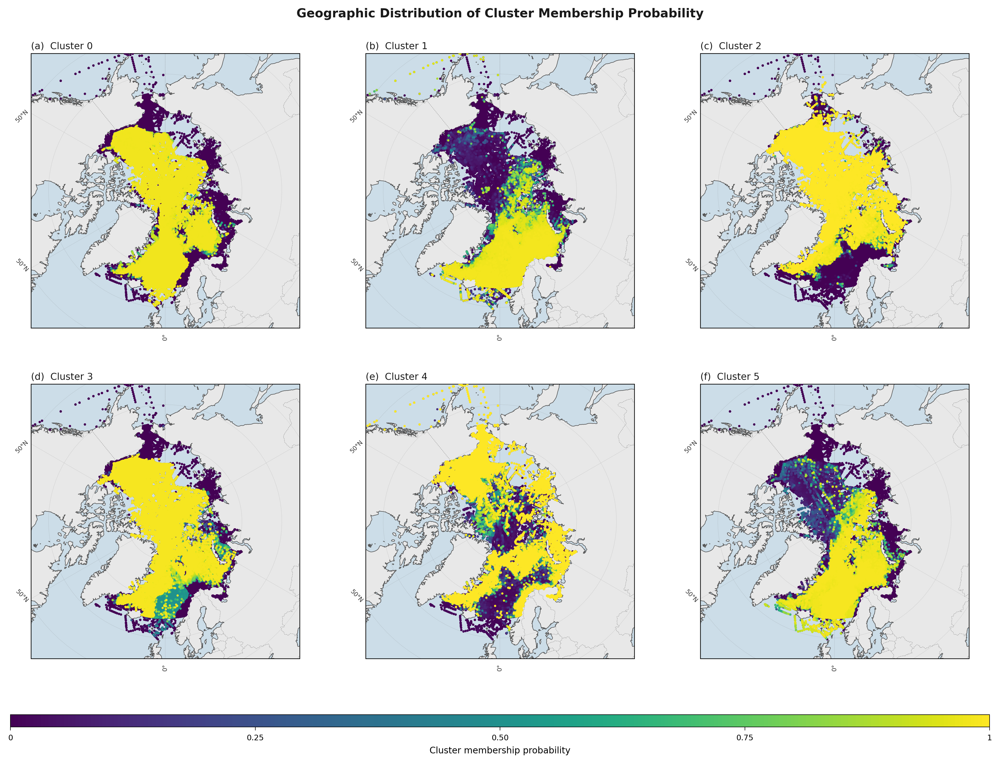

In [5]:
"""
Geographic Cluster Probability Plotter — Arctic, 2×3 layout
=============================================================
One shared sequential colormap across all 6 panels.
Each panel shows all points coloured by P(cluster k).

Usage
-----
    from plot_cluster_probabilities import plot_cluster_probabilities
    plot_cluster_probabilities(df)
"""

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.colorbar as mcolorbar

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("[Info] cartopy not found — using plain axes.\n"
          "       Install: conda install -c conda-forge cartopy")

# ---------------------------------------------------------------------------
# Default column names
# ---------------------------------------------------------------------------
_LAT_COL       = "Latitude_[deg_N]"
_LON_COL       = "Longitude_[deg_E]"
_PROB_COLS     = [f"prob_cluster_{k}" for k in range(6)]
_CLUSTER_NAMES = [f"Cluster {k}" for k in range(6)]

# Shared colormap: white/very-pale → deep blue-purple
# Visually neutral (no per-cluster hue bias), prints well in greyscale too.
# Swap to "plasma", "viridis", "cividis" etc. via the `cmap` parameter.
_DEFAULT_CMAP = "viridis"   # dark blue (0) → yellow (1)

def _resolve_cmap(name: str):
    """Return a matplotlib colormap by name."""
    try:
        return mpl.colormaps[name]
    except KeyError:
        print(f"[Info] Colormap '{name}' not found — falling back to 'viridis'.")
        return mpl.colormaps["viridis"]


def _add_cartopy_features(ax):
    ax.add_feature(cfeature.LAND,
                   facecolor="#e8e8e8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.OCEAN,
                   facecolor="#ccdde8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.COASTLINE,
                   linewidth=0.5, edgecolor="#555555", zorder=2)
    ax.add_feature(cfeature.BORDERS,
                   linewidth=0.3, edgecolor="#999999",
                   linestyle="--", zorder=2)


def _add_gridlines(ax):
    gl = ax.gridlines(
        draw_labels=True, linewidth=0.3,
        color="#666666", alpha=0.45, linestyle=":",
        x_inline=False, y_inline=False,
    )
    gl.top_labels   = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 5.5, "color": "#333333"}
    gl.ylabel_style = {"size": 5.5, "color": "#333333"}


def plot_cluster_probabilities(
    df: pd.DataFrame,
    lat_col: str        = _LAT_COL,
    lon_col: str        = _LON_COL,
    prob_cols: list     = _PROB_COLS,
    cluster_names: list = _CLUSTER_NAMES,
    output_path: str    = "cluster_probabilities_arctic.pdf",
    dpi: int            = 300,
    point_size: float   = 4.0,
    figsize: tuple      = (13.0, 9.5),
    title: str          = "Geographic Distribution of Cluster Membership Probability",
    subtitle: str       = None,
    cmap: str           = "viridis",
    font_family: str    = "DejaVu Sans",
) -> plt.Figure:
    """
    Plot all 6 cluster probabilities on a 2x3 Arctic map grid.

    All panels share one colormap (white → saturated colour, 0 → 1).
    A single shared colorbar sits below the panels.

    Parameters
    ----------
    df            : DataFrame containing lat, lon, and probability columns.
    lat_col       : Latitude column name.
    lon_col       : Longitude column name.
    prob_cols     : Six probability column names (prob_cluster_0 … 5).
    cluster_names : Panel title labels.
    output_path   : Save path (.pdf for journal submission).
    dpi           : Resolution for raster outputs.
    point_size    : Scatter marker size. Reduce for very dense data.
    figsize       : (width, height) in inches.
    title         : Figure-level title.
    subtitle      : Optional italic second line.
    cmap          : Colormap name. Supports cmocean names
                    ('cmocean_matter_r', 'cmocean_thermal', etc.)
                    or any matplotlib name ('YlOrRd', 'plasma', …).
    font_family   : Matplotlib font family string.
    """

    n_clusters = len(prob_cols)   # 6
    nrows, ncols = 2, 3

    lats  = df[lat_col].values.astype(float)
    lons  = df[lon_col].values.astype(float)
    probs = df[prob_cols].values.astype(float)   # (N, 6)

    colormap = _resolve_cmap(cmap)
    norm     = mcolors.Normalize(vmin=0, vmax=1)

    rc = {
        "font.family":       font_family,
        "font.size":         8,
        "axes.titlesize":    9,
        "axes.labelsize":    8,
        "xtick.labelsize":   6.5,
        "ytick.labelsize":   6.5,
        "axes.linewidth":    0.6,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.direction":   "out",
        "ytick.direction":   "out",
        "figure.dpi":        dpi,
        "savefig.dpi":       dpi,
        "pdf.fonttype":      42,
        "ps.fonttype":       42,
    }

    with mpl.rc_context(rc):
        fig = plt.figure(figsize=figsize, facecolor="white")

        # ── title block ───────────────────────────────────────────────────
        fig.text(0.5, 0.985, title,
                 ha="center", va="top", fontsize=11,
                 fontweight="semibold", color="#1a1a1a")
        if subtitle:
            fig.text(0.5, 0.958, subtitle,
                     ha="center", va="top", fontsize=8,
                     color="#555555", style="italic")

        top_margin = 0.925 if not subtitle else 0.900

        # ── gridspec: panels + colorbar row ───────────────────────────────
        # Extra bottom row (height_ratios last entry) holds the shared colorbar.
        gs = gridspec.GridSpec(
            nrows + 1, ncols,
            figure=fig,
            top=top_margin, bottom=0.04,
            left=0.03, right=0.97,
            hspace=0.30, wspace=0.08,
            height_ratios=[1] * nrows + [0.045],
        )

        axes = []

        for k in range(n_clusters):
            row, col = divmod(k, ncols)
            p     = probs[:, k]
            order = np.argsort(p)   # paint low-prob first, high-prob on top

            # ── axes ──────────────────────────────────────────────────────
            if HAS_CARTOPY:
                ax = fig.add_subplot(
                    gs[row, col],
                    projection=ccrs.NorthPolarStereo(central_longitude=0),
                )
                # Full Arctic: everything north of ~55 °N
                ax.set_extent([-180, 180, 55, 90], crs=ccrs.PlateCarree())
                _add_cartopy_features(ax)
                _add_gridlines(ax)
                transform = ccrs.PlateCarree()
            else:
                ax = fig.add_subplot(gs[row, col])
                ax.set_facecolor("#ccdde8")
                ax.set_xlim(-180, 180)
                ax.set_ylim(55, 90)
                ax.set_xlabel("Longitude (°E)", labelpad=2)
                ax.set_ylabel("Latitude (°N)",  labelpad=2)
                ax.tick_params(which="both", length=2.5)
                transform = None

            # ── scatter ───────────────────────────────────────────────────
            sc_kw = dict(
                c=p[order], cmap=colormap, norm=norm,
                s=point_size, linewidths=0,
                rasterized=True, zorder=3,
            )
            if transform:
                sc_kw["transform"] = transform

            sc = ax.scatter(lons[order], lats[order], **sc_kw)

            # ── panel label ───────────────────────────────────────────────
            label = f"({chr(97 + k)})  {cluster_names[k]}"
            ax.set_title(label, pad=4, fontsize=8.5,
                         fontweight="medium", loc="left", color="#1a1a1a")

            axes.append(ax)

        # ── shared colorbar in the bottom GridSpec row ────────────────────
        # Span all three columns for a wide, unobtrusive bar.
        cbar_ax = fig.add_subplot(gs[nrows, :])
        sm = mpl.cm.ScalarMappable(cmap=colormap, norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
        cbar.set_label("Cluster membership probability", fontsize=8, labelpad=4)
        cbar.ax.tick_params(labelsize=7, length=3, width=0.5)
        cbar.outline.set_linewidth(0.5)
        cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
        cbar.set_ticklabels(["0", "0.25", "0.50", "0.75", "1"])

        fig.savefig(output_path, bbox_inches="tight",
                    facecolor=fig.get_facecolor())
        print(f"Saved → {output_path}")

    return fig

# Plot the cluster probabilities on the Arctic map

fig = plot_cluster_probabilities(
    df=df,
    title="Geographic Distribution of Cluster Membership Probability",
    output_path="arctic_cluster_map.pdf",
    )
plt.show()

Generating Linear Depth Plot...
Saved → arctic_clusters_probs_depth_linear.pdf
Generating Log Depth Plot...
Saved → arctic_clusters_probs_depth_log.pdf


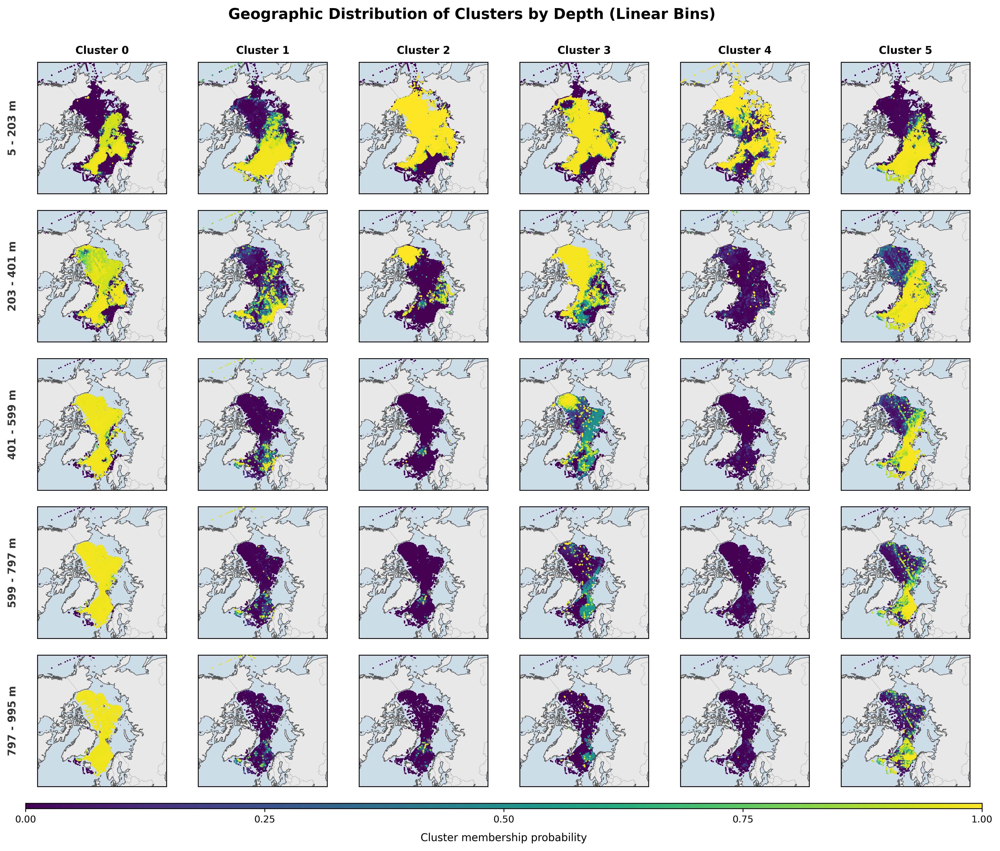

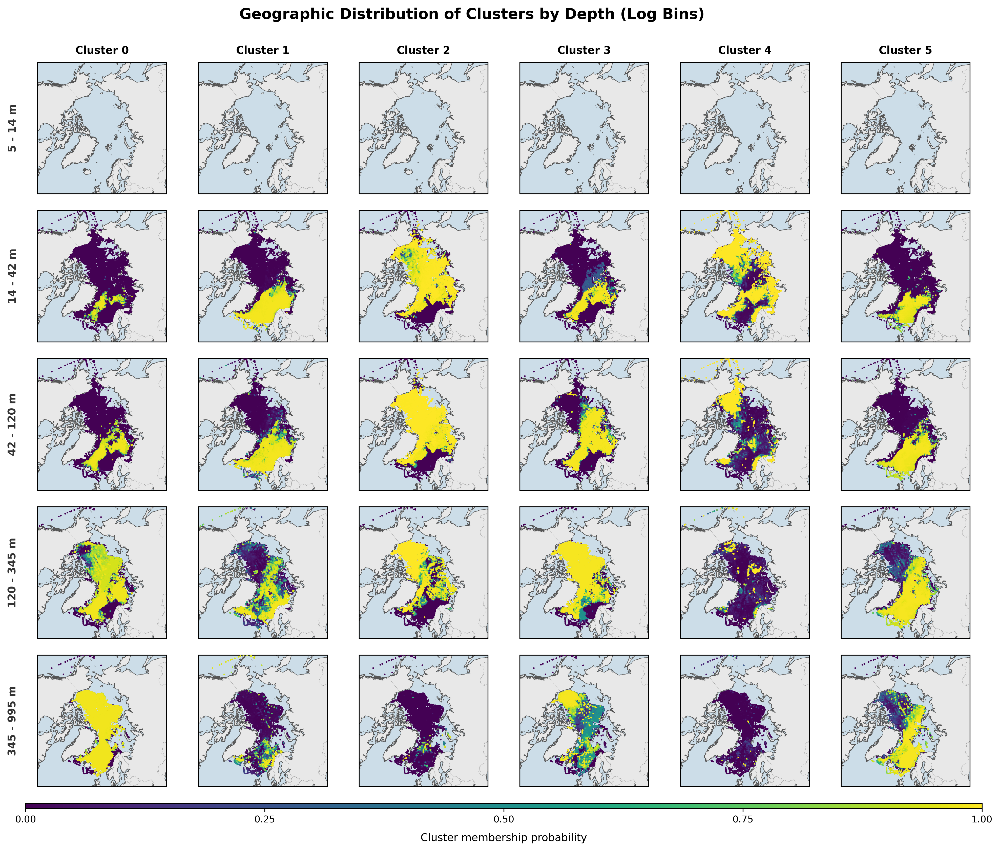

In [7]:
"""
Geographic Cluster Probability Plotter by Depth Bin (5x6 Grid)
==============================================================
Rows: 5 depth bins (linear or log-scaled)
Columns: 6 clusters
Shared sequential colormap across all 30 panels.
"""

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("[Info] cartopy not found — using plain axes.\n"
          "       Install: conda install -c conda-forge cartopy")


def _add_cartopy_features(ax):
    """Add land, ocean, coastline, and borders to Cartopy axes."""
    ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.OCEAN, facecolor="#ccdde8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor="#555555", zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="#999999", linestyle="--", zorder=2)


def compute_depth_bins(df: pd.DataFrame, depth_col: str, scale: str, n_bins: int) -> np.ndarray:
    """Calculate bin edges based on the data's min/max and the chosen scale."""
    d_min = df[depth_col].min()
    d_max = df[depth_col].max()
    
    if scale == "linear":
        return np.linspace(d_min, d_max, n_bins + 1)
    elif scale == "log":
        # Log scale cannot start at 0. Shift safe_min to 1.0 (or higher) for geomspace.
        safe_min = max(1.0, d_min) 
        bins = np.geomspace(safe_min, d_max, n_bins + 1)
        # Force the first bin edge to capture any values between actual min (e.g., 0) and safe_min
        if d_min < safe_min:
            bins[0] = d_min - 1e-5 
        return bins
    else:
        raise ValueError("scale must be 'linear' or 'log'")


def plot_cluster_depth_grid(
    df: pd.DataFrame,
    depth_scale: str    = "linear",
    n_bins: int         = 5,
    lat_col: str        = "Latitude_[deg_N]",
    lon_col: str        = "Longitude_[deg_E]",
    depth_col: str      = "z_bin",
    prob_cols: list     = None,
    cluster_names: list = None,
    output_path: str    = None,
    dpi: int            = 300,
    point_size: float   = 2.0,
    figsize: tuple      = (14.0, 12.0),
    cmap: str           = "viridis",
) -> plt.Figure:
    
    if prob_cols is None:
        prob_cols = [f"prob_cluster_{k}" for k in range(6)]
    if cluster_names is None:
        cluster_names = [f"Cluster {k}" for k in range(6)]
        
    n_clusters = len(prob_cols)
    bins = compute_depth_bins(df, depth_col, depth_scale, n_bins)
    
    colormap = plt.get_cmap(cmap)
    norm = mcolors.Normalize(vmin=0, vmax=1)

    rc = {
        "font.family": "sans-serif",
        "font.size": 8,
        "axes.titlesize": 10,
        "figure.dpi": dpi,
        "savefig.dpi": dpi,
    }

    with mpl.rc_context(rc):
        fig = plt.figure(figsize=figsize, facecolor="white")
        title = f"Geographic Distribution of Clusters by Depth ({depth_scale.title()} Bins)"
        fig.text(0.5, 0.94, title, ha="center", va="top", fontsize=14, fontweight="semibold")

        # GridSpec: 5 rows for maps + 1 narrow row for the shared colorbar
        gs = gridspec.GridSpec(
            n_bins + 1, n_clusters,
            figure=fig,
            top=0.88, bottom=0.06,
            left=0.08, right=0.98,
            hspace=0.15, wspace=0.05,
            height_ratios=[1] * n_bins + [0.04],
        )

        # Build the 5x6 grid
        for row in range(n_bins):
            d_min, d_max = bins[row], bins[row+1]
            
            # Filter data for this specific depth bin
            mask = (df[depth_col] > d_min) & (df[depth_col] <= d_max)
            df_subset = df[mask]
            
            lats = df_subset[lat_col].values.astype(float)
            lons = df_subset[lon_col].values.astype(float)
            probs = df_subset[prob_cols].values.astype(float) if not df_subset.empty else None

            for col in range(n_clusters):
                # 1. Setup Axes
                if HAS_CARTOPY:
                    ax = fig.add_subplot(gs[row, col], projection=ccrs.NorthPolarStereo(central_longitude=0))
                    ax.set_extent([-180, 180, 55, 90], crs=ccrs.PlateCarree())
                    _add_cartopy_features(ax)
                    transform = ccrs.PlateCarree()
                else:
                    ax = fig.add_subplot(gs[row, col])
                    ax.set_facecolor("#ccdde8")
                    ax.set_xlim(-180, 180)
                    ax.set_ylim(55, 90)
                    ax.set_xticks([])
                    ax.set_yticks([])
                    transform = None

                # 2. Scatter Data (if bin isn't empty)
                if probs is not None and len(probs) > 0:
                    p = probs[:, col]
                    order = np.argsort(p)  # Low probs plot first, high probs on top
                    sc_kw = dict(
                        c=p[order], cmap=colormap, norm=norm,
                        s=point_size, linewidths=0, zorder=3,
                    )
                    if transform:
                        sc_kw["transform"] = transform
                    
                    ax.scatter(lons[order], lats[order], **sc_kw)

                # 3. Top Row Labels (Clusters)
                if row == 0:
                    ax.set_title(cluster_names[col], pad=8, fontweight="bold")

                # 4. Left Column Labels (Depth Bins)
                if col == 0:
                    # Format bin label. If max is large, omit decimals.
                    label = f"{max(0, d_min):.0f} - {d_max:.0f} m"
                    ax.annotate(
                        label, xy=(-0.15, 0.5), xycoords="axes fraction",
                        rotation=90, va="center", ha="right",
                        fontsize=10, fontweight="bold", color="#333333"
                    )

        # Add shared colorbar at the bottom spanning all columns
        cbar_ax = fig.add_subplot(gs[n_bins, :])
        sm = mpl.cm.ScalarMappable(cmap=colormap, norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
        cbar.set_label("Cluster membership probability", fontsize=10, labelpad=8)
        cbar.ax.tick_params(labelsize=9, length=3)
        cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
        
        if output_path:
            fig.savefig(output_path, bbox_inches="tight", facecolor=fig.get_facecolor())
            print(f"Saved → {output_path}")

    return fig

# =============================================================================
# Execution & Testing
# =============================================================================
if __name__ == "__main__":

    # 1. Plot Linear Depth Bins
    print("Generating Linear Depth Plot...")
    fig_lin = plot_cluster_depth_grid(
        df, 
        depth_scale="linear",
        output_path="arctic_clusters_probs_depth_linear.pdf"
    )

    # 2. Plot Logarithmic Depth Bins
    print("Generating Log Depth Plot...")
    fig_log = plot_cluster_depth_grid(
        df, 
        depth_scale="log",
        output_path="arctic_clusters_probs_depth_log.pdf"
    )
    
    plt.show()

Generating Plot with Custom Depth Bins...
Saved → arctic_clusters_custom_depths.pdf


<Figure size 4200x4800 with 0 Axes>

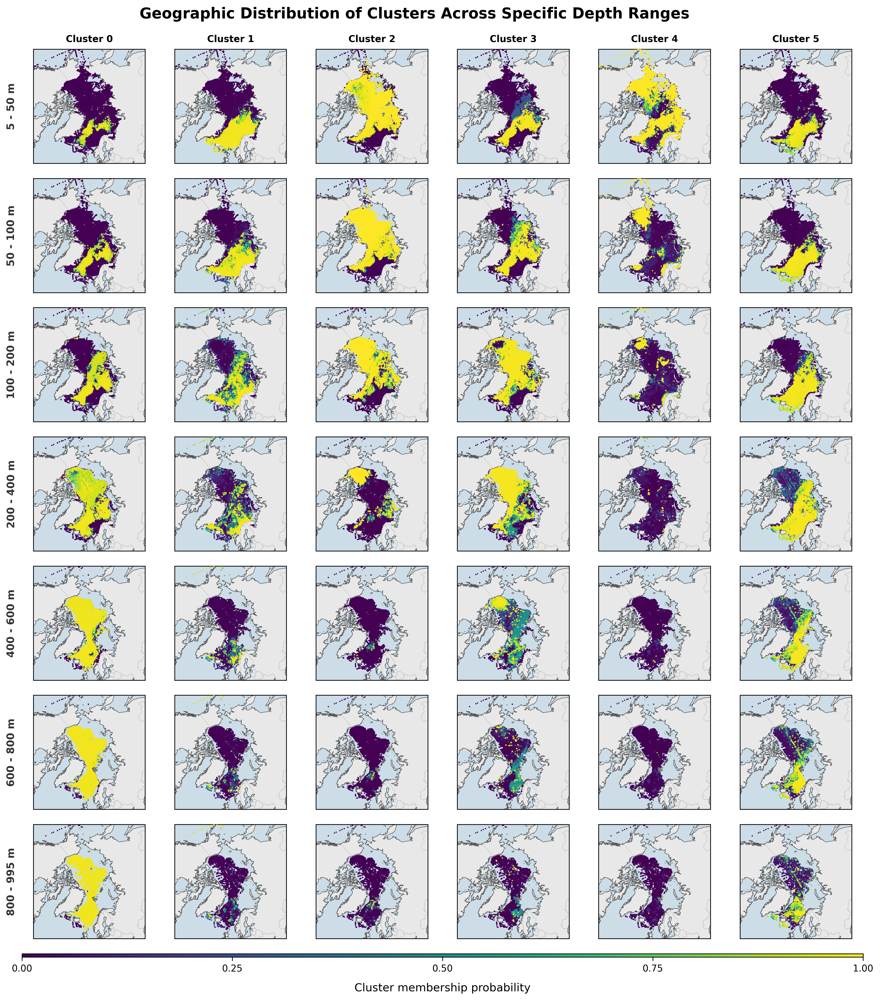

In [9]:
"""
Geographic Cluster Probability Plotter by Custom Depth Bins (7x6 Grid)
======================================================================
Rows: 7 explicit depth bins (5-50m, 50-100m, etc.)
Columns: 6 clusters
Shared sequential colormap across all 42 panels.
"""

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("[Info] cartopy not found — using plain axes.\n"
          "       Install: conda install -c conda-forge cartopy")

# ---------------------------------------------------------------------------
# Plotting Helpers
# ---------------------------------------------------------------------------
def _add_cartopy_features(ax):
    """Add land, ocean, coastline, and borders to Cartopy axes."""
    ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.OCEAN, facecolor="#ccdde8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor="#555555", zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="#999999", linestyle="--", zorder=2)

def plot_custom_depth_grid(
    df: pd.DataFrame,
    depth_bins: list    = [5, 50, 100, 200, 400, 600, 800, 995],
    lat_col: str        = "Latitude_[deg_N]",
    lon_col: str        = "Longitude_[deg_E]",
    depth_col: str      = "z_bin",
    prob_cols: list     = None,
    cluster_names: list = None,
    output_path: str    = "arctic_clusters_custom_depths.pdf",
    dpi: int            = 300,
    point_size: float   = 2.0,
    figsize: tuple      = (14.0, 16.0),
    cmap: str           = "viridis",
) -> plt.Figure:
    
    if prob_cols is None:
        prob_cols = [f"prob_cluster_{k}" for k in range(6)]
    if cluster_names is None:
        cluster_names = [f"Cluster {k}" for k in range(6)]
        
    n_clusters = len(prob_cols)
    n_rows = len(depth_bins) - 1
    
    colormap = plt.get_cmap(cmap)
    norm = mcolors.Normalize(vmin=0, vmax=1)

    rc = {
        "font.family": "sans-serif",
        "font.size": 8,
        "axes.titlesize": 10,
        "figure.dpi": dpi,
        "savefig.dpi": dpi,
    }

    with mpl.rc_context(rc):
        fig = plt.figure(figsize=figsize, facecolor="white")
        title = "Geographic Distribution of Clusters Across Specific Depth Ranges"
        fig.text(0.5, 0.93, title, ha="center", va="top", fontsize=16, fontweight="semibold")

        # GridSpec: Rows for map panels + 1 narrow row for the shared colorbar
        gs = gridspec.GridSpec(
            n_rows + 1, n_clusters,
            figure=fig,
            top=0.89, bottom=0.04,
            left=0.08, right=0.98,
            hspace=0.15, wspace=0.05,
            height_ratios=[1] * n_rows + [0.03],
        )

        for row in range(n_rows):
            d_min = depth_bins[row]
            d_max = depth_bins[row+1]
            
            # Filter data for this specific depth bin
            # Uses >= for the bottom and < for the top, ensuring points exactly on edges are binned once
            if row == n_rows - 1:
                # Include the upper bound on the final bin
                mask = (df[depth_col] >= d_min) & (df[depth_col] <= d_max)
            else:
                mask = (df[depth_col] >= d_min) & (df[depth_col] < d_max)
                
            df_subset = df[mask]
            
            lats = df_subset[lat_col].values.astype(float)
            lons = df_subset[lon_col].values.astype(float)
            probs = df_subset[prob_cols].values.astype(float) if not df_subset.empty else None

            for col in range(n_clusters):
                # 1. Setup Axes
                if HAS_CARTOPY:
                    ax = fig.add_subplot(gs[row, col], projection=ccrs.NorthPolarStereo(central_longitude=0))
                    ax.set_extent([-180, 180, 55, 90], crs=ccrs.PlateCarree())
                    _add_cartopy_features(ax)
                    transform = ccrs.PlateCarree()
                else:
                    ax = fig.add_subplot(gs[row, col])
                    ax.set_facecolor("#ccdde8")
                    ax.set_xlim(-180, 180)
                    ax.set_ylim(55, 90)
                    ax.set_xticks([])
                    ax.set_yticks([])
                    transform = None

                # 2. Scatter Data (if bin isn't empty)
                if probs is not None and len(probs) > 0:
                    p = probs[:, col]
                    order = np.argsort(p)  # Low probs plot first, high probs on top
                    sc_kw = dict(
                        c=p[order], cmap=colormap, norm=norm,
                        s=point_size, linewidths=0, zorder=3,
                    )
                    if transform:
                        sc_kw["transform"] = transform
                    
                    ax.scatter(lons[order], lats[order], **sc_kw)

                # 3. Top Row Labels (Clusters)
                if row == 0:
                    ax.set_title(cluster_names[col], pad=8, fontweight="bold")

                # 4. Left Column Labels (Depth Bins)
                if col == 0:
                    label = f"{d_min} - {d_max} m"
                    ax.annotate(
                        label, xy=(-0.15, 0.5), xycoords="axes fraction",
                        rotation=90, va="center", ha="right",
                        fontsize=11, fontweight="bold", color="#333333"
                    )

        # Add shared colorbar at the bottom spanning all columns
        cbar_ax = fig.add_subplot(gs[n_rows, :])
        sm = mpl.cm.ScalarMappable(cmap=colormap, norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
        cbar.set_label("Cluster membership probability", fontsize=12, labelpad=10)
        cbar.ax.tick_params(labelsize=10, length=4)
        cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
        
        if output_path:
            fig.savefig(output_path, bbox_inches="tight", facecolor=fig.get_facecolor())
            print(f"Saved → {output_path}")

    return fig

# =============================================================================
# Execution
# =============================================================================
# Plot using the custom predefined depth bins
print("Generating Plot with Custom Depth Bins...")
fig = plot_custom_depth_grid(
    df, 
    depth_bins=[5, 50, 100, 200, 400, 600, 800, 995],
    output_path="arctic_clusters_custom_depths.pdf"
)

plt.show()

Generating Plot with Custom Depth Bins...
Saved → arctic_clusters_custom_depths_colours.pdf


<Figure size 4200x4800 with 0 Axes>

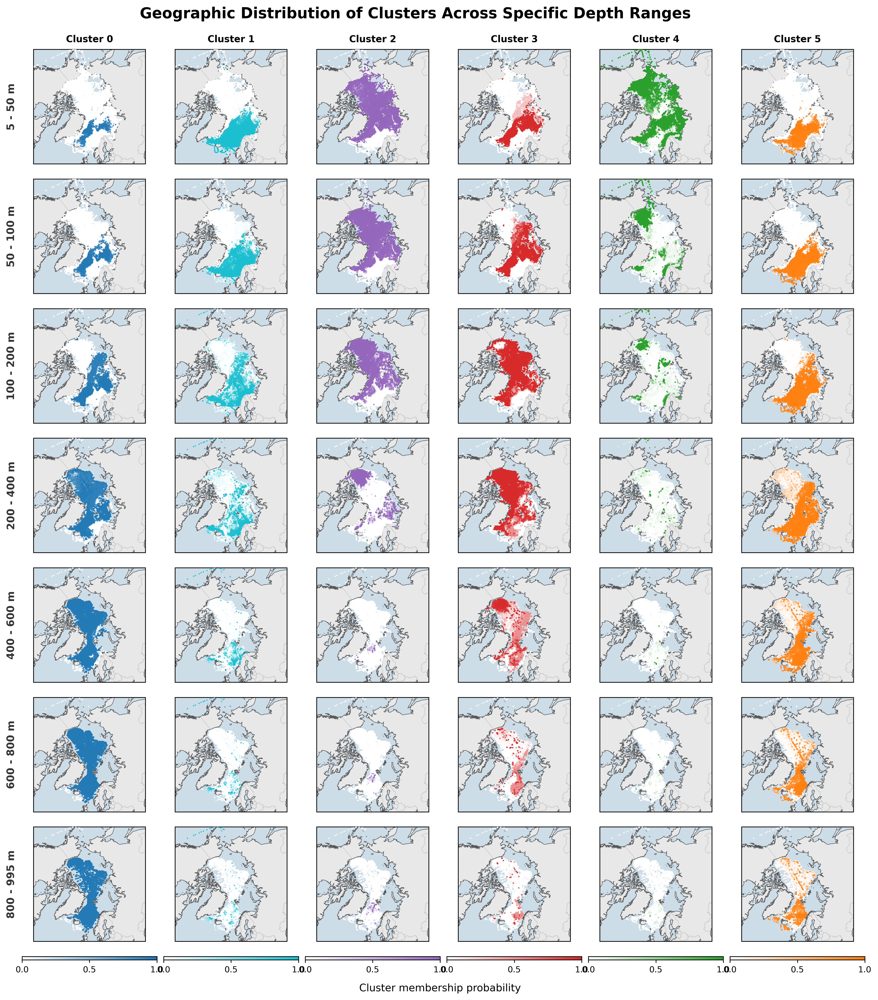

In [17]:
"""
Geographic Cluster Probability Plotter by Custom Depth Bins (7x6 Grid)
======================================================================
Rows: 7 explicit depth bins (5-50m, 50-100m, etc.)
Columns: 6 clusters
Colormap: Each cluster (column) uses a custom colormap fading from white 
          to its specific Tab10 color. Individual colorbars are at the bottom.
"""

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False
    print("[Info] cartopy not found — using plain axes.\n"
          "       Install: conda install -c conda-forge cartopy")

# ---------------------------------------------------------------------------
# Plotting Helpers
# ---------------------------------------------------------------------------
def _add_cartopy_features(ax):
    """Add land, ocean, coastline, and borders to Cartopy axes."""
    ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.OCEAN, facecolor="#ccdde8", linewidth=0, zorder=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor="#555555", zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="#999999", linestyle="--", zorder=2)

def plot_custom_depth_grid(
    df: pd.DataFrame,
    depth_bins: list    = [5, 50, 100, 200, 400, 600, 800, 995],
    lat_col: str        = "Latitude_[deg_N]",
    lon_col: str        = "Longitude_[deg_E]",
    depth_col: str      = "z_bin",
    prob_cols: list     = None,
    cluster_names: list = None,
    output_path: str    = "arctic_clusters_custom_depths.pdf",
    dpi: int            = 300,
    point_size: float   = 2.0,
    figsize: tuple      = (14.0, 16.0),
) -> plt.Figure:
    
    if prob_cols is None:
        prob_cols = [f"prob_cluster_{k}" for k in range(6)]
    if cluster_names is None:
        cluster_names = [f"Cluster {k}" for k in range(6)]
        
    n_clusters = len(prob_cols)
    n_rows = len(depth_bins) - 1
    
    # Define custom cluster colors and create fading colormaps (White -> Color)
    tab10 = plt.colormaps['tab10'].colors
    cluster_base_colors = {
        0: tab10[0], 1: tab10[9], 2: tab10[4],
        3: tab10[3], 4: tab10[2], 5: tab10[1],
    }
    
    cluster_cmaps = []
    for k in range(n_clusters):
        c = cluster_base_colors.get(k, tab10[k % len(tab10)])
        cmap = mcolors.LinearSegmentedColormap.from_list(f'cmap_cluster_{k}', ['white', c])
        cluster_cmaps.append(cmap)
        
    norm = mcolors.Normalize(vmin=0, vmax=1)

    rc = {
        "font.family": "sans-serif",
        "font.size": 8,
        "axes.titlesize": 10,
        "figure.dpi": dpi,
        "savefig.dpi": dpi,
    }

    with mpl.rc_context(rc):
        fig = plt.figure(figsize=figsize, facecolor="white")
        title = "Geographic Distribution of Clusters Across Specific Depth Ranges"
        fig.text(0.5, 0.93, title, ha="center", va="top", fontsize=16, fontweight="semibold")

        # GridSpec: Rows for map panels + 1 narrow row for the colorbars
        gs = gridspec.GridSpec(
            n_rows + 1, n_clusters,
            figure=fig,
            top=0.89, bottom=0.04,
            left=0.08, right=0.98,
            hspace=0.15, wspace=0.05,
            height_ratios=[1] * n_rows + [0.03],
        )

        for row in range(n_rows):
            d_min = depth_bins[row]
            d_max = depth_bins[row+1]
            
            # Filter data for this specific depth bin
            if row == n_rows - 1:
                mask = (df[depth_col] >= d_min) & (df[depth_col] <= d_max)
            else:
                mask = (df[depth_col] >= d_min) & (df[depth_col] < d_max)
                
            df_subset = df[mask]
            
            lats = df_subset[lat_col].values.astype(float)
            lons = df_subset[lon_col].values.astype(float)
            probs = df_subset[prob_cols].values.astype(float) if not df_subset.empty else None

            for col in range(n_clusters):
                # 1. Setup Axes
                if HAS_CARTOPY:
                    ax = fig.add_subplot(gs[row, col], projection=ccrs.NorthPolarStereo(central_longitude=0))
                    ax.set_extent([-180, 180, 55, 90], crs=ccrs.PlateCarree())
                    _add_cartopy_features(ax)
                    transform = ccrs.PlateCarree()
                else:
                    ax = fig.add_subplot(gs[row, col])
                    ax.set_facecolor("#ccdde8")
                    ax.set_xlim(-180, 180)
                    ax.set_ylim(55, 90)
                    ax.set_xticks([])
                    ax.set_yticks([])
                    transform = None

                # 2. Scatter Data using column-specific colormap
                if probs is not None and len(probs) > 0:
                    p = probs[:, col]
                    order = np.argsort(p)
                    sc_kw = dict(
                        c=p[order], cmap=cluster_cmaps[col], norm=norm,
                        s=point_size, linewidths=0, zorder=3,
                    )
                    if transform:
                        sc_kw["transform"] = transform
                    
                    ax.scatter(lons[order], lats[order], **sc_kw)

                # 3. Top Row Labels (Clusters)
                if row == 0:
                    ax.set_title(cluster_names[col], pad=8, fontweight="bold")

                # 4. Left Column Labels (Depth Bins)
                if col == 0:
                    label = f"{d_min} - {d_max} m"
                    ax.annotate(
                        label, xy=(-0.15, 0.5), xycoords="axes fraction",
                        rotation=90, va="center", ha="right",
                        fontsize=11, fontweight="bold", color="#333333"
                    )

        # Bottom row: Render individual colorbars per column
        for col in range(n_clusters):
            cbar_ax = fig.add_subplot(gs[n_rows, col])
            sm = mpl.cm.ScalarMappable(cmap=cluster_cmaps[col], norm=norm)
            sm.set_array([])
            cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
            
            cbar.ax.tick_params(labelsize=9, length=3)
            # Use fewer ticks so they don't overlap in the narrow columns
            cbar.set_ticks([0, 0.5, 1.0])
            
            if col == 2: # Add the label near the center colorbars
                cbar.set_label("Cluster membership probability", fontsize=11, labelpad=10, x=1.0)
        
        if output_path:
            fig.savefig(output_path, bbox_inches="tight", facecolor=fig.get_facecolor())
            print(f"Saved → {output_path}")

    return fig

# =============================================================================
# Execution
# =============================================================================
# Plot using the custom predefined depth bins
print("Generating Plot with Custom Depth Bins...")
fig = plot_custom_depth_grid(
    df, 
    depth_bins=[5, 50, 100, 200, 400, 600, 800, 995],
    output_path="arctic_clusters_custom_depths_colours.pdf"
)

plt.show()

## Plot 6x6 property plots for each cluster

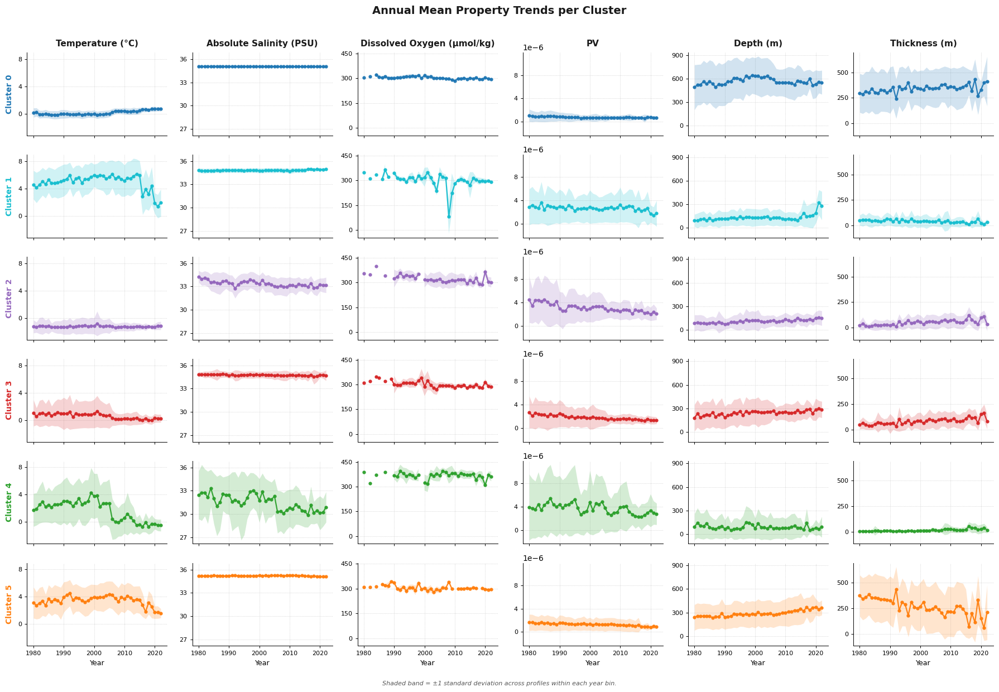

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# ── 1. Cluster colours ────────────────────────────────────────────────────────
tab10 = plt.colormaps['tab10'].colors
colors = {
    0: tab10[0], 1: tab10[9], 2: tab10[4],
    3: tab10[3], 4: tab10[2], 5: tab10[1],
}

# ── 2. Column → publication title ────────────────────────────────────────────
clean_names = {
    'Conservative_Temperature_[deg_C]':          'Temperature (°C)',
    'Absolute_Salinity_[PSU]':                   'Absolute Salinity (PSU)',
    'Dissolved_Oxygen_[micro_mol_per_kg]':        'Dissolved Oxygen (µmol/kg)',
    'PV':                                         'PV',
    'z_bin':                                      'Depth (m)',
    'Thickness_[m]':                              'Thickness (m)',
}

n_clusters = 6
cols       = list(clean_names.keys())
n_props    = len(cols)

# ── 3. Pre-compute yearly means (± std) per cluster for every property ────────
# For each non-Thickness column: group the rows that belong to cluster i,
# then take the mean and std of that property per year_bin.
# For Thickness: use thickness_df (separate dataframe) as before.

yearly = {}   # yearly[i][col] = DataFrame with index=year, cols=['mean','std']

for i in range(n_clusters):
    yearly[i] = {}
    cluster_df = df[df['mean_cluster'] == i]

    for col in cols:
        if col == 'Thickness_[m]':
            stats = (thickness_df
                     .groupby('year_bin')[f'thickness_prob_cluster_{i}']
                     .agg(['mean', 'std']))
        else:
            stats = (cluster_df
                     .groupby('year_bin')[col]
                     .agg(['mean', 'std']))

        yearly[i][col] = stats

# ── 4. Figure ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    n_clusters, n_props,
    figsize=(18, 12),
    sharex=True,
    sharey='col',
)

for i in range(n_clusters):
    c = colors[i]

    for j, col in enumerate(cols):
        ax    = axes[i, j]
        stats = yearly[i][col]

        # ── line + shaded std band ────────────────────────────────────────
        ax.plot(
            stats.index, stats['mean'],
            color=c, linewidth=1.6, marker='o',
            markersize=3.5, alpha=0.95, zorder=3,
        )
        ax.fill_between(
            stats.index,
            stats['mean'] - stats['std'],
            stats['mean'] + stats['std'],
            color=c, alpha=0.20, linewidth=0, zorder=2,
        )

        # ── spine / grid styling ─────────────────────────────────────────
        ax.grid(True, linestyle=':', linewidth=0.6, alpha=0.65, color='#aaaaaa')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(0.7)
        ax.spines['bottom'].set_linewidth(0.7)
        ax.tick_params(axis='both', labelsize=8, length=3, width=0.7)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=5))
        ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=4, prune='both'))

        # ── top-row property titles ───────────────────────────────────────
        if i == 0:
            ax.set_title(
                clean_names[col],
                fontsize=11, fontweight='bold', pad=8, color='#1a1a1a',
            )

        # ── left-column cluster labels ────────────────────────────────────
        if j == 0:
            ax.set_ylabel(
                f'Cluster {i}',
                fontsize=10, fontweight='bold', color=c, labelpad=6,
            )

        # ── bottom-row x-axis label ───────────────────────────────────────
        if i == n_clusters - 1:
            ax.set_xlabel('Year', fontsize=9, labelpad=4)

# ── 5. Figure-level labels ────────────────────────────────────────────────────
fig.suptitle(
    'Annual Mean Property Trends per Cluster',
    fontsize=14, fontweight='semibold', y=1.01, color='#1a1a1a',
)
fig.text(
    0.5, -0.005,
    'Shaded band = ±1 standard deviation across profiles within each year bin.',
    ha='center', fontsize=8, color='#555555', style='italic',
)

plt.tight_layout(rect=[0, 0.01, 1, 1])
plt.savefig('cluster_property_trends.pdf', bbox_inches='tight',
            dpi=300, facecolor='white')
plt.show()

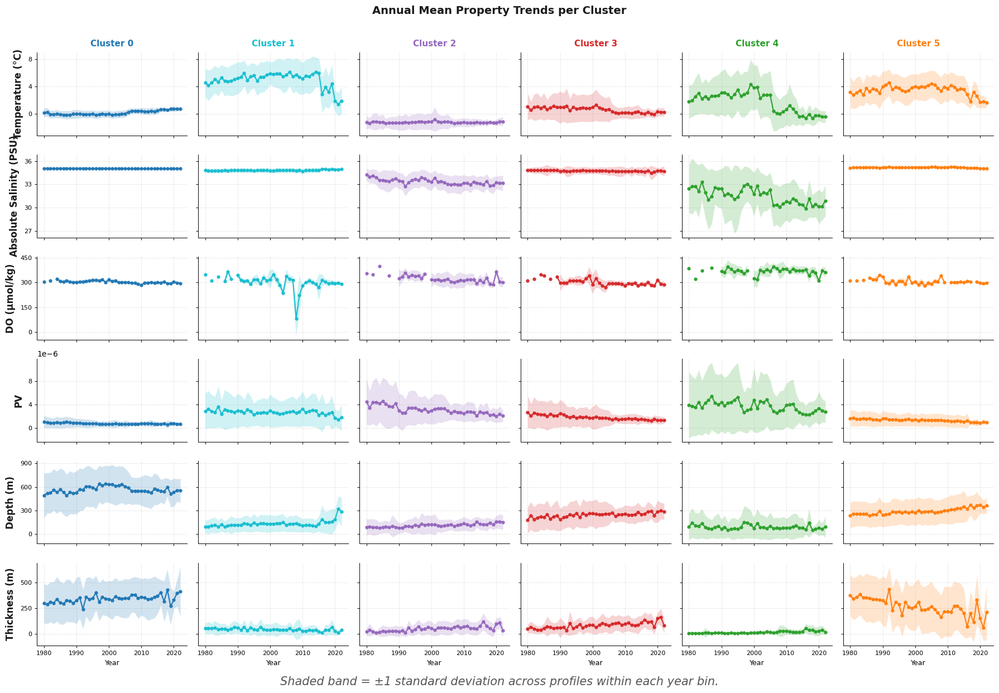

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# ── 1. Cluster colours ────────────────────────────────────────────────────────
tab10 = plt.colormaps['tab10'].colors
colors = {
    0: tab10[0], 1: tab10[9], 2: tab10[4],
    3: tab10[3], 4: tab10[2], 5: tab10[1],
}

# ── 2. Column → publication title ────────────────────────────────────────────
clean_names = {
    'Conservative_Temperature_[deg_C]':          'Temperature (°C)',
    'Absolute_Salinity_[PSU]':                   'Absolute Salinity (PSU)',
    'Dissolved_Oxygen_[micro_mol_per_kg]':        'DO (µmol/kg)',
    'PV':                                         'PV',
    'z_bin':                                      'Depth (m)',
    'Thickness_[m]':                              'Thickness (m)',
}

n_clusters = 6
cols       = list(clean_names.keys())
n_props    = len(cols)

# ── 3. Pre-compute yearly means (± std) per cluster for every property ────────
# For each non-Thickness column: group the rows that belong to cluster i,
# then take the mean and std of that property per year_bin.
# For Thickness: use thickness_df (separate dataframe) as before.

yearly = {}   # yearly[i][col] = DataFrame with index=year, cols=['mean','std']

for i in range(n_clusters):
    yearly[i] = {}
    cluster_df = df[df['mean_cluster'] == i]

    for col in cols:
        if col == 'Thickness_[m]':
            stats = (thickness_df
                     .groupby('year_bin')[f'thickness_prob_cluster_{i}']
                     .agg(['mean', 'std']))
        else:
            stats = (cluster_df
                     .groupby('year_bin')[col]
                     .agg(['mean', 'std']))

        yearly[i][col] = stats

# ── 4. Figure ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    n_props, n_clusters,
    figsize=(18, 12),
    sharex=True,
    sharey='row',
)

for j, col in enumerate(cols):
    for i in range(n_clusters):
        ax    = axes[j, i]
        c     = colors[i]
        stats = yearly[i][col]

        # ── line + shaded std band ────────────────────────────────────────
        ax.plot(
            stats.index, stats['mean'],
            color=c, linewidth=1.6, marker='o',
            markersize=3.5, alpha=0.95, zorder=3,
        )
        ax.fill_between(
            stats.index,
            stats['mean'] - stats['std'],
            stats['mean'] + stats['std'],
            color=c, alpha=0.20, linewidth=0, zorder=2,
        )

        # ── spine / grid styling ─────────────────────────────────────────
        ax.grid(True, linestyle=':', linewidth=0.6, alpha=0.65, color='#aaaaaa')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(0.7)
        ax.spines['bottom'].set_linewidth(0.7)
        ax.tick_params(axis='both', labelsize=8, length=3, width=0.7)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=5))
        ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=4, prune='both'))

        # ── top-row cluster titles ────────────────────────────────────────
        if j == 0:
            ax.set_title(
                f'Cluster {i}',
                fontsize=11, fontweight='bold', pad=8, color=c,
            )

        # ── left-column property labels ───────────────────────────────────
        if i == 0:
            ax.set_ylabel(
                clean_names[col],
                fontsize=12, fontweight='bold', color='#1a1a1a', labelpad=6,
            )

        # ── bottom-row x-axis label ───────────────────────────────────────
        if j == n_props - 1:
            ax.set_xlabel('Year', fontsize=10, labelpad=4)

# ── 5. Figure-level labels ────────────────────────────────────────────────────
fig.suptitle(
    'Annual Mean Property Trends per Cluster',
    fontsize=10, fontweight='semibold', y=1.01, color='#1a1a1a',
)
fig.text(
    0.5, -0.005,
    'Shaded band = ±1 standard deviation across profiles within each year bin.',
    ha='center', fontsize=15, color='#555555', style='italic',
)

plt.tight_layout(rect=[0, 0.01, 1, 1])
plt.savefig('cluster_property_trends.pdf', bbox_inches='tight',
            dpi=300, facecolor='white')
plt.show()